# Activity - Estimating Lifetime

- Use Telco Churn dataset and build a Kaplan Meier survival analysis.
- Compare lifetime between different payment methods.

## 0. Setup

In [62]:
# Colab ไม่มี lifelines ติดมาให้ / เครื่องตัวเองก็รันครั้งเดียวพอ
!pip install -q lifelines


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lifelines

print("lifelines :", lifelines.__version__)

lifelines : 0.30.3


## 1. Load dataset

In [64]:
df = pd.read_csv('Telco+Churn.csv')

print("shape :", df.shape)
print("cols  :", list(df.columns))
df.head()

shape : (7043, 21)
cols  : ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [65]:
# survival analysis ใช้แค่ 3 คอลัมน์นี้
#   tenure        -> T  duration   อยู่กับเรามากี่เดือน
#   Churn         -> E  event      ยกเลิกจริงไหม
#   PaymentMethod -> group         ตัวที่โจทย์สั่งให้เทียบ
print(df[['tenure', 'Churn', 'PaymentMethod']].head(10))
print()
print("missing:")
print(df[['tenure', 'Churn', 'PaymentMethod']].isna().sum())

   tenure Churn              PaymentMethod
0       1    No           Electronic check
1      34    No               Mailed check
2       2   Yes               Mailed check
3      45    No  Bank transfer (automatic)
4       2   Yes           Electronic check
5       8   Yes           Electronic check
6      22    No    Credit card (automatic)
7      10    No               Mailed check
8      28   Yes           Electronic check
9      62    No  Bank transfer (automatic)

missing:
tenure           0
Churn            0
PaymentMethod    0
dtype: int64


## 2. mapping Churn into event 1/0

Churn = Yes  -> 1  เห็นเหตุการณ์จริง (ตาย)<br/>
Churn = No   -> 0  censored ยังอยู่ ณ วันเก็บข้อมูล ไม่ได้แปลว่าจะอยู่ตลอดไป

In [66]:
print(df['Churn'].value_counts(), "\n")

df['event'] = (df['Churn'] == 'Yes').astype(int)

# เช็คว่าแมพถูก ตัวเลขต้องตรงกับข้างบน แล้วต้องไม่มีช่องหลุดมุม
print(pd.crosstab(df['Churn'], df['event']))
print("\ncensored rate = %.3f" % (1 - df['event'].mean()))

Churn
No     5174
Yes    1869
Name: count, dtype: int64 

event     0     1
Churn            
No     5174     0
Yes       0  1869

censored rate = 0.735


## 3. checking tenure feature

In [67]:
print(df['tenure'].describe(), "\n")
print("tenure == 0 :", (df['tenure'] == 0).sum(), "rows")
print(df.loc[df['tenure'] == 0, ['tenure', 'Churn', 'TotalCharges', 'PaymentMethod']].head())

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64 

tenure == 0 : 11 rows
      tenure Churn TotalCharges              PaymentMethod
488        0    No               Bank transfer (automatic)
753        0    No                            Mailed check
936        0    No                            Mailed check
1082       0    No                            Mailed check
1340       0    No                 Credit card (automatic)


In [68]:
# Dorp tenure == 0 (อยู่กับเรามา 0 เดือน -> ลูกค้าใหม่)

before = len(df)
df = df[df['tenure'] > 0].copy()

print("dropped :", before - len(df))
print("shape   :", df.shape)

dropped : 11
shape   : (7032, 22)


## 4. ประกอบ T กับ E

In [69]:
T = df['tenure']       # duration
E = df['event']        # event observed

print("T : n=%d  range %d - %d เดือน" % (len(T), T.min(), T.max()))
print("E : events=%d  censored=%d" % (E.sum(), (E == 0).sum()))

T : n=7032  range 1 - 72 เดือน
E : events=1869  censored=5163


## 5. Kaplan-Meier for all dataset (baseline)

ยังไม่แยกกลุ่ม เอาไว้เป็นเส้นอ้างอิงว่าภาพรวมหน้าตายังไง

In [70]:
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
kmf.fit(T, event_observed=E, label='All customers')

# ตาราง S(t) ทีละ step เริ่มที่ 1.0 แล้วลดลงทุกครั้งที่มีคน churn
print(kmf.survival_function_.head(10))

          All customers
timeline               
0.0            1.000000
1.0            0.945961
2.0            0.927835
3.0            0.913725
4.0            0.901045
5.0            0.891111
6.0            0.884826
7.0            0.876713
8.0            0.869933
9.0            0.862394


In [71]:
print("median survival time :", kmf.median_survival_time_)

for t in [6, 12, 24, 48, 72]:
    print("S(%2d) = %.3f" % (t, kmf.survival_function_at_times(t).iloc[0]))

median survival time : inf
S( 6) = 0.885
S(12) = 0.843
S(24) = 0.789
S(48) = 0.709
S(72) = 0.593


> median go to `inf` becauase S(t) never reach 0.5

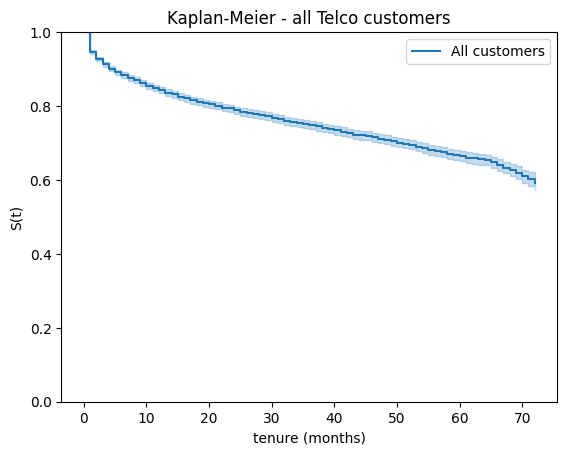

In [72]:
kmf.plot_survival_function()
plt.title('Kaplan-Meier - all Telco customers')
plt.xlabel('tenure (months)')
plt.ylabel('S(t)')
plt.ylim(0, 1)
plt.show()

## 6. Kaplan-Meier for each PaymentMethod

In [73]:
methods = df['PaymentMethod'].value_counts().index.tolist()   # sort from biggest to smallest group
print(methods)

['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']


Electronic check           n=2365  events=1071  median=47.0
Mailed check               n=1604  events= 308  median=inf
Bank transfer (automatic)  n=1542  events= 258  median=inf
Credit card (automatic)    n=1521  events= 232  median=inf


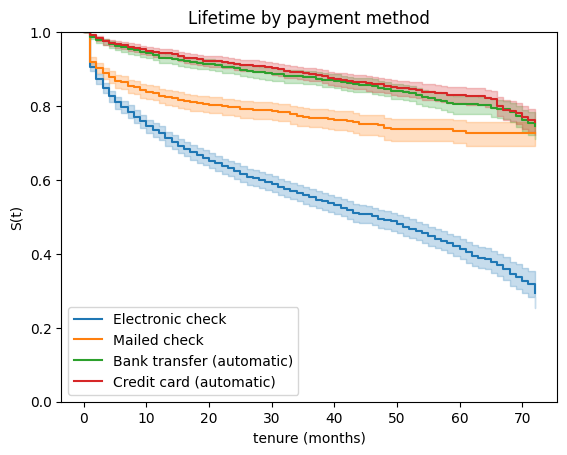

In [74]:
ax = plt.subplot(111)
fitters = {}

for m in methods:
    mask = df['PaymentMethod'] == m
    k = KaplanMeierFitter()
    k.fit(T[mask], event_observed=E[mask], label=m)
    k.plot_survival_function(ax=ax, ci_show=True)      # ci_show ไว้ดูว่าเส้นเหลื่อมกันไหม
    fitters[m] = k

    print("%-26s n=%4d  events=%4d  median=%s"
          % (m, mask.sum(), E[mask].sum(), k.median_survival_time_))

plt.title('Lifetime by payment method')
plt.xlabel('tenure (months)')
plt.ylabel('S(t)')
plt.ylim(0, 1)
plt.show()

> 3 ใน 4 กลุ่ม median = `inf` ทำให้ เทียบ "อายุเฉลี่ย" ด้วย median ไม่ได้<br/>
> ใช้ 2 อย่างแทน: **S(t) ที่เวลาคงที่** (12/24/48 เดือน) และ **RMST** = พื้นที่ใต้เส้น
> ถึงเดือนที่ 72 ตีความได้ว่า "โดยเฉลี่ยอยู่กี่เดือน ภายในกรอบ 72 เดือน"

In [75]:
from lifelines.utils import restricted_mean_survival_time as rmst

rows = []
for m, k in fitters.items():
    mask = df['PaymentMethod'] == m
    rows.append({
        'PaymentMethod': m,
        'n':        int(mask.sum()),
        'events':   int(E[mask].sum()),
        'median':   k.median_survival_time_,
        'S(12)':    k.survival_function_at_times(12).iloc[0],
        'S(24)':    k.survival_function_at_times(24).iloc[0],
        'S(48)':    k.survival_function_at_times(48).iloc[0],
        'RMST(72)': rmst(k, t=72),
    })

summary = pd.DataFrame(rows).sort_values('RMST(72)', ascending=False)
print(summary.to_string(index=False))

            PaymentMethod    n  events  median    S(12)    S(24)    S(48)  RMST(72)
  Credit card (automatic) 1521     232     inf 0.944802 0.912765 0.855388 63.810876
Bank transfer (automatic) 1542     258     inf 0.931131 0.902220 0.847383 62.999594
             Mailed check 1604     308     inf 0.828110 0.796522 0.739521 56.362564
         Electronic check 2365    1071    47.0 0.727032 0.624107 0.492719 41.243145


In [76]:

s24 = summary['S(24)'].sort_values(ascending=False)
s24_max     = s24.iloc[0]   # แถวที่ 0 หลัง sort = สูงสุด
s24_closest = s24.iloc[1]   # แถวที่ 1 = ใกล้ max ที่สุด
s24_min     = s24.iloc[3]

print(f"S(24) minimum different: {s24_max - s24_closest}")
print(f"S(24) maximum different: {s24_max - s24_min}")

S(24) minimum different: 0.010544955037039672
S(24) maximum different: 0.28865724878695187


## 7. Check is it just a coincidence?  (log-rank test)

H0 = ทุกกลุ่มมี survival curve เดียวกัน

In [77]:
from lifelines.statistics import multivariate_logrank_test

res = multivariate_logrank_test(T, df['PaymentMethod'], E)
res.print_summary()

print("p-value =", res.p_value)

p-value = 3.0665292229500084e-187


In [78]:
# pairwise logrank test
from lifelines.statistics import pairwise_logrank_test

pair = pairwise_logrank_test(T, df['PaymentMethod'], E)

# pandas use e-01 (2 degit) but this p have 3 ditgit (e-113)
print(pair.summary[['test_statistic', 'p']].to_string(
    formatters={'p': lambda x: np.format_float_scientific(
        x, precision=6, unique=False, exp_digits=3
    )}
))

                                                   test_statistic             p
Bank transfer (automatic) Credit card (automatic)        0.868295 3.514278e-001
                          Electronic check             510.035059 6.231417e-113
                          Mailed check                  51.071855 8.904593e-013
Credit card (automatic)   Electronic check             539.740177 2.147615e-119
                          Mailed check                  64.815174 8.226320e-016
Electronic check          Mailed check                 152.455455 5.038297e-035


## 8. Summary

- กลุ่มที่อยู่สั้นที่สุดคือ `Electronic check` ส่วนที่อยู่นานที่สุดคือ `Credit card (automatic)`
- S(24) ต่างกันมากที่สุดที่ 0.288 เเละน้อยที่สุดที่ 0.0105
- log-rank ภาพรวม p = ไม่ปฏิเสธ H0 -> มีนัยะสำคัญทางสถิติว่า survival curve ต่างกัน
- คู่ที่ log-rank บอกว่า **ไม่** ต่างกันคือ `Credit card (automatic)` กับ `Bank transfer (automatic)` (p > 0.05) เพราะ ไม่มีหลักฐานเพียงพอที่จะสรุปว่า survival curves ของทั้งคู่ต่างกัน (ทั้งคู่อาจจะมี survival curves เหมือนกัน)

ตีความเชิงธุรกิจ: 

ลูกค้าที่ใช้ `Credit card (automatic)` กับ `Bank transfer (automatic)` มีแนวโน้มของระยะเวลาการเป็นลูกค้า (customer lifetime) สูงกว่ากลุ่มอื่น 

โดยที่ `Credit card (automatic)` เเละ `Bank transfer (automatic)` อาจมี survival curves เหมือนกัน ในขณะที่ `Mailed check` เเละ `Electronic check` มี survival curves ต่างกัน
